# Signal Audit 6: Checks of the Columns with No Formula

`gld_player_signals_daily`, September 2026, five brands, all rows (latest `_version`), aggregates only. The checks asked after the review:

1. **Load times:** `_ingested_at` and `_processed_at` against each other (within 5 to 10 minutes) and against the snapshot date.
2. **Country, currency, language:** distribution per brand, and a single format (no "TR" next to "tr").
3. **Categorical columns** (`lifecycle_stage`, `value_tier`, `lifetime_value_tier`, `churn_band`, `risk_band`, `prev_*`): distribution; it should not be uniform.
4. **Ids:** `player_id` (digits only, length) and `tenant_id` (UUID, lower case).
5. **Snapshot date against the transactions:** which day the data of each snapshot comes from.
6. **Tax:** a share of the GGR, never above the GGR or the stake.

In [1]:
%reload_ext autoreload
%autoreload 2

import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display

RUN_S3 = True    # True the first time: reads S3 (needs `aws sso login`) and fills cache/
os.environ["RUN_S3"] = "1" if RUN_S3 else "0"

sys.path.insert(0, str(Path.cwd().parents[1]))   # the repo root: signal_audit is a package
from signal_audit.data import audit
from signal_audit.checks import evidence as ev
from signal_audit.checks import extra_checks as x

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 120)
cfg = audit.load_config()
print(f"period {cfg['period']['start']} to {cfg['period']['end']}, brands {cfg['brands']}")


def split(frame, col, names=("p1", "p50", "p99")):
    """A column of [p1, p50, p99] lists as three columns."""
    values = [v if v is not None and len(v) == len(names) else [float("nan")] * len(names) for v in frame[col]]   # None: no rows
    return frame.drop(columns=col).join(pd.DataFrame(values, index=frame.index, columns=[f"{col} {n}" for n in names]))

period 2026-09-01 to 2026-09-30, brands [14, 23, 64, 72, 73]


## 1. Load Times

- **Process minus ingest (minutes):** `_processed_at - _ingested_at`. Expected: between 0 and 10 minutes.
- **After the end of the snapshot day (hours):** `_ingested_at` (or `_processed_at`) minus `snapshot_date + 1 day, 00:00 UTC`. A daily snapshot should be loaded a few hours after its day ends. The lake keeps only the last version of each row, and the daily files are rewritten for 7 days, so this is the time of the **last** rewrite.

,rows,within 10 min %,processed_before_ingested,process_minus_ingest_min p50,process_minus_ingest_min p99,ingest_after_day_end_h p50,process_after_day_end_h p50
brand_id,,,,,,,
14,3266844,58.22,0.0,0.06,153331.79,147.03,147.03
23,5748513,72.18,0.0,0.06,153308.68,147.03,147.03
64,3825179,66.68,0.0,0.06,153319.28,147.03,147.03
72,6277949,68.67,0.0,0.06,153331.79,147.03,147.03
73,7983864,70.26,0.0,0.06,153319.28,147.03,147.03


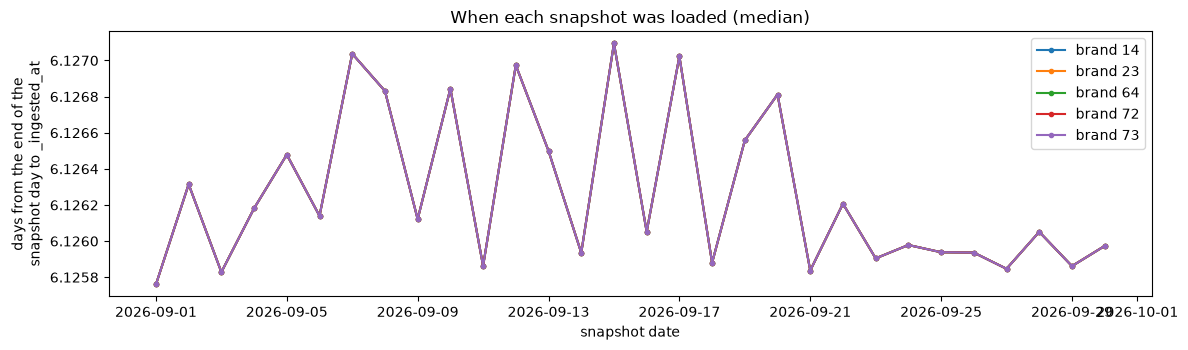

In [2]:
t = x.load_times(cfg)
for c in ("process_minus_ingest_min", "ingest_after_day_end_h", "process_after_day_end_h"):
    t = split(t, c)
t["within 10 min %"] = 100 * t["within_10_min"] / t["rows"]
cols = ["rows", "within 10 min %", "processed_before_ingested", "process_minus_ingest_min p50", "process_minus_ingest_min p99",
        "ingest_after_day_end_h p50", "process_after_day_end_h p50"]
display(t.groupby("brand_id")[cols].agg({"rows": "sum", "within 10 min %": "median", "processed_before_ingested": "sum",
                                         "process_minus_ingest_min p50": "median", "process_minus_ingest_min p99": "max",
                                         "ingest_after_day_end_h p50": "median", "process_after_day_end_h p50": "median"}).round(2))
fig, ax = plt.subplots(figsize=(12, 3.6))
for b, g in t.groupby("brand_id"):
    ax.plot(pd.to_datetime(g["snapshot_date"]), g["ingest_after_day_end_h p50"] / 24, marker="o", ms=3, label=f"brand {b}")
ax.set(xlabel="snapshot date", ylabel="days from the end of the\nsnapshot day to _ingested_at", title="When each snapshot was loaded (median)")
ax.legend(); plt.tight_layout(); plt.show()

## 2. Country, Currency and Language

Format of each column (all brands): distinct values, % in upper case, % in lower case (mixed: the rest), lengths and NULL. Then the values per brand.

In [3]:
values = x.categories(cfg)
display(x.formats(values).set_index("column").round(2))
for col in ("country", "currency", "language"):
    p = values[values["col"] == col].pivot_table(index="value", columns="brand_id", values="rows", aggfunc="sum", fill_value=0)
    print(col)
    display((100 * p / p.sum()).round(2).loc[p.sum(axis=1).sort_values(ascending=False).index].head(20))

,distinct,rows,null %,upper %,lower %,lengths
column,,,,,,
churn_band,6,27102349,0.0,0.00,0.0,"3, 4, 7, 8, 10"
country,1,27102349,0.0,100.00,0.0,0
currency,11,27102349,0.0,100.00,0.0,"0, 3, 4"
language,1,27102349,0.0,100.00,0.0,0
lifecycle_stage,6,27102349,0.0,0.00,0.0,"3, 6, 7, 10, 11"
lifetime_value_tier,6,27102349,0.0,0.00,0.0,"5, 6, 7, 8, 10"
param_version,1,27102349,0.0,100.00,0.0,22
prev_churn_band,7,27102349,0.0,0.02,0.0,"0, 3, 4, 7, 8, 10"
prev_lifecycle_stage,7,27102349,0.0,0.02,0.0,"0, 3, 6, 7, 10, 11"


country


brand_id,14,23,64,72,73
value,,,,,
,100.0,100.0,100.0,100.0,100.0


currency


brand_id,14,23,64,72,73
value,,,,,
,88.34,85.44,86.02,88.33,88.92
TRY,11.66,14.55,13.98,7.75,5.71
EUR,0.00,0.00,0.00,1.46,5.31
PLN,0.00,0.00,0.00,2.46,0.00
AUD,0.00,0.00,0.00,0.00,0.04
INR,0.00,0.00,0.00,0.00,0.01
USDT,0.00,0.00,0.00,0.01,0.00
USD,0.00,0.00,0.00,0.00,0.00
NZD,0.00,0.00,0.00,0.00,0.00


language


brand_id,14,23,64,72,73
value,,,,,
,100.0,100.0,100.0,100.0,100.0


## 3. Categorical Columns: Not Uniform

Share of each value (all brands). Tiers and bands should fall from the lowest to the highest (many low-value players, few top ones), not be flat.

In [4]:
cats = ["lifecycle_stage", "value_tier", "lifetime_value_tier", "churn_band", "risk_band",
        "prev_lifecycle_stage", "prev_value_tier", "prev_churn_band", "prev_risk_band"]
fig, axes = plt.subplots(3, 3, figsize=(14, 9))
for ax, c in zip(axes.flat, cats):
    g = values[(values["col"] == c)].groupby(values["value"].fillna("NULL"))["rows"].sum().sort_values(ascending=False)
    ax.bar(g.index.astype(str), 100 * g / g.sum(), color="#2a78d6")
    ax.axhline(100 / max(len(g), 1), color="black", lw=1, label="uniform")
    ax.set(title=c, ylabel="% of rows"); ax.tick_params(axis="x", rotation=45, labelsize=8)
axes.flat[0].legend(); plt.tight_layout(); plt.show()

## 4. Ids

`player_id`: type, NULL, length of the text, rows with anything that is not a digit. `tenant_id`: distinct values, UUID format, lower case.

In [5]:
display(x.ids(cfg).T)
l = x.id_lengths(cfg).pivot_table(index="length", columns="brand_id", values="rows", fill_value=0)
display((100 * l / l.sum()).round(2))

,0
player_id_type,INTEGER
rows,27102349
player_id_null,0.0
player_id_min_len,5
player_id_max_len,8
player_id_not_digits,0.0
player_id_min,78645
player_id_max,19489064
tenant_id_type,VARCHAR
tenant_ids,5


brand_id,14,23,64,72,73
length,,,,,
5,0.02,0.00,0.00,0.00,0.00
6,0.33,0.00,0.00,0.00,0.00
7,8.79,23.85,21.41,6.63,16.51
8,90.86,76.15,78.59,93.37,83.49


## 5. Snapshot Date against the Transactions

Which day the data of the snapshot of day D comes from: for each shift s, % of players whose `days_since_bet` of day D equals their real recency of day D + s (from the gaming table). s = 0 means the data is of day D; s > 0, of later days; s < 0, of earlier days (stale). Local files only.

In [6]:
_, shifts = ev.recency_evidence()
display(shifts.pivot_table(index="shift", columns="brand", values="match %", aggfunc="median").round(1))

brand,14,23,64,72,73
shift,,,,,
-3,5.9,9.8,5.0,4.6,6.7
-2,5.5,9.5,5.0,4.1,6.7
-1,6.1,10.7,5.1,4.1,6.8
0,5.9,11.8,5.1,4.4,7.1
1,5.8,9.2,5.2,4.0,6.2
2,5.8,9.1,4.6,3.7,6.3
3,5.7,8.2,4.5,3.6,5.9
4,5.1,7.8,4.2,3.5,5.8
5,5.1,7.0,3.4,3.0,5.3


## 6. Tax

Per window: rows with tax, negative tax, tax above the GGR (GGR above 0), tax above the stake, and quantiles (1, 50, 99 %) of tax / GGR and tax / stake (rows with tax).

In [7]:
tx = split(split(x.tax(cfg), "tax_over_ggr"), "tax_over_stake")
tx["with tax %"] = 100 * tx["with_tax"] / tx["rows"]
display(tx.round(4))

,brand_id,window,rows,tax_null,tax_zero,with_tax,negative,above_ggr,above_stake,tax_over_ggr p1,tax_over_ggr p50,tax_over_ggr p99,tax_over_stake p1,tax_over_stake p50,tax_over_stake p99,with tax %
0,14,l180d,3266844,0.0,3266844.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0
1,14,l90d,3266844,0.0,3266844.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0
2,14,today,3266844,0.0,3266844.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0
3,23,l180d,5748513,0.0,5748513.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0
4,23,l90d,5748513,0.0,5748513.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0
5,23,today,5748513,0.0,5748513.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0
6,64,l180d,3825179,0.0,3825179.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0
7,64,l90d,3825179,0.0,3825179.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0
8,64,today,3825179,0.0,3825179.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0
9,72,l180d,6277949,0.0,6277949.0,0.0,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,0.0


## 7. Bonus GGR against the Gaming Table

`bonus_ggr_eur_today` of each player-day against the sum of `bonus_ggr_eur` of `gld_player_gaming_daily` (playable bonus stake minus playable bonus wins, checked at 100% in the gaming report). It passes when $|x - f| \le 0.01 + 0.001\,|f|$. `not_in_gaming`: player-days with no row in the gaming table (counted as 0).

In [8]:
b = x.bonus_vs_gaming(cfg)
b = b.assign(**{"pass %": 100 * b["ok"] / b["rows"], "higher %": 100 * b["higher"] / b["rows"],
               "lower %": 100 * b["lower"] / b["rows"], "not in gaming %": 100 * b["not_in_gaming"] / b["rows"]})
display(b.set_index("brand_id").round(2))

,rows,ok,higher,lower,not_in_gaming,pass %,higher %,lower %,not in gaming %
brand_id,,,,,,,,,
14,3266844,3266811.0,22.0,11.0,3215160.0,100.0,0.0,0.0,98.42
23,5748513,5748287.0,162.0,64.0,5556109.0,100.0,0.0,0.0,96.65
64,3825179,3825154.0,16.0,9.0,3752342.0,100.0,0.0,0.0,98.10
72,6277949,6277873.0,51.0,25.0,6205631.0,100.0,0.0,0.0,98.85
73,7983864,7983795.0,48.0,21.0,7826038.0,100.0,0.0,0.0,98.02


## 8. Impossible Sessions: Sports Betting or Casino?

In the gaming table, 71% of the `play_secs` over 24 h are sports bets (providers 58 and 50): a sports bet stays open until the match ends. 
Are the impossible session values of the signals table the same thing? % of rows with an impossible value per group:
- **day:** `play_secs_today > 24 h`, by what the player played that day (sports only, casino only, both);
- **player:** mean session over 1 day and negative gap between sessions (90-day windows), by whether the player bet on sports in September.

In [9]:
sp = x.sessions_by_product(cfg)
t = sp.groupby(["rule", "grp"])[["rows", "impossible"]].sum()
t["impossible %"] = 100 * t["impossible"] / t["rows"]
t["share of the impossible %"] = 100 * t["impossible"] / t.groupby(level="rule")["impossible"].transform("sum")
display(t.round(2))
b = sp.assign(pct=100 * sp["impossible"] / sp["rows"]).pivot_table(index=["rule", "grp"], columns="brand_id", values="pct")
display(b.round(2))

rows  impossible  impossible %  share of the impossible %
rule                     grp                                                                         
gap between sessions < 0 bets on sports   477694      7328.0          1.53                      39.92
                         casino only     1568844     11027.0          0.70                      60.08
mean session > 1 day     bets on sports   520964      2993.0          0.57                      64.28
                         casino only     2052791      1663.0          0.08                      35.72
play_secs_today > 24 h   both              46182      6750.0         14.62                      34.82
                         casino only      424265      4439.0          1.05                      22.90
                         sports only       58927      8196.0         13.91                      42.28

brand_id                                    14     23    64     72     73
rule                     grp                                             
gap between sessions < 0 bets on sports   1.25   0.81  0.45   1.62   2.32
                         casino only      1.12   0.07  0.83   1.47   0.74
mean session > 1 day     bets on sports   0.20   0.29  0.02   0.09   1.04
                         casino only      0.09   0.06  0.04   0.10   0.12
play_secs_today > 24 h   both            14.69  15.57  5.29   6.35  18.12
                         casino only      1.05   0.98  0.72   1.07   1.33
                         sports only     12.71  11.84  6.31  13.76  15.36

## 9. Findings

To fill in after running the notebook.